# Cavity QED Coupling Lab

Python companion to the AMO Toolkit page [Cavity QED Coupling Lab](https://amotoolkit.com/pages/cavity-qed.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/cavity-qed.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Coupling rates from geometry
All rates are given as ordinary frequencies (÷2π), in MHz, and κ and γ are **half-widths**, as on the page:

* mode volume $V = \pi w_0^2 L/4$; $g_0 = \xi\sqrt{3\pi\Gamma c^3/(2\omega^2 V)}$
* $\kappa = \mathrm{FSR}/(2F)$ with $\mathrm{FSR} = c/2nL$; $\gamma = \Gamma/2$
* cooperativity $C = g_0^2/\kappa\gamma$ (equal to the Purcell factor in this convention), $\beta = C/(1+C)$
* saturation photon number $n_0 = \gamma^2/2g_0^2$, critical atom number $N_0 = 2/C$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
c = 299792458.0

def cavity(F=50000, L_mm=0.5, w0_um=25, n=1, lam_nm=780.241, Gamma_MHz=6.065, xi=1.0):
    L, w0, lam = L_mm * 1e-3, w0_um * 1e-6, lam_nm * 1e-9
    omega, Gam = 2 * np.pi * c / lam, 2 * np.pi * Gamma_MHz * 1e6
    V = np.pi * w0**2 * L / 4
    g0 = xi * np.sqrt(3 * np.pi * Gam * c**3 / (2 * omega**2 * V)) / (2 * np.pi * 1e6)
    FSR = c / (2 * n * L)
    kap = FSR / (2 * F) / 1e6
    gam = Gamma_MHz / 2
    C = g0**2 / (kap * gam)
    beta = C / (1 + C)
    R = ((-np.pi + np.sqrt(np.pi**2 + 4 * F**2)) / (2 * F)) ** 2
    return dict(g0=g0, kappa=kap, gamma=gam, C=C, V_halflam3=V / (lam / 2) ** 3, FSR_GHz=FSR / 1e9,
                linewidth_MHz=2 * kap, n0=gam**2 / (2 * g0**2), N0=2 / C, beta_pct=100 * beta,
                beta_exact_pct=100 * beta * kap / (kap + gam), F_for_kappa_eq_g=F * kap / g0, R_pct=100 * R)

def regime(r):
    if r["g0"] > r["kappa"] and r["g0"] > r["gamma"]: return "strong coupling"
    return "Purcell (bad cavity)" if r["C"] > 1 else "weak coupling"

r = cavity()    # page defaults: Rb-87 D2, F = 50 000, L = 0.5 mm, w0 = 25 µm
for k, v in r.items():
    print(f"{k:>16} = {v:.4g}")
print("regime:", regime(r))

              g0 = 9.256
           kappa = 2.998
           gamma = 3.033
               C = 9.424
      V_halflam3 = 4.134e+06
         FSR_GHz = 299.8
   linewidth_MHz = 5.996
              n0 = 0.05367
              N0 = 0.2122
        beta_pct = 90.41
  beta_exact_pct = 44.94
F_for_kappa_eq_g = 1.619e+04
           R_pct = 99.99
regime: strong coupling

## 2. Where does the photon go?
After a π-pulse the atom emits either into the cavity mode or into free space. For a weakly excited, resonant system the exact probability of a cavity photon is $\frac{C}{1+C}\frac{\kappa}{\kappa+\gamma}$, and the bad-cavity β = C/(1+C) overestimates it unless κ ≫ γ. (The page's §04 animates this with quantum trajectories.)

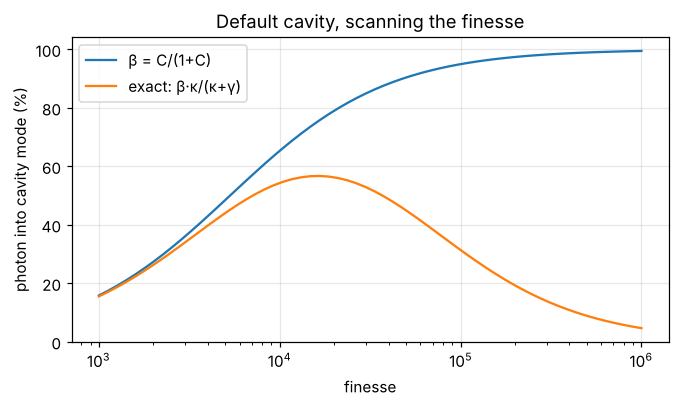

In [2]:
Fs = np.logspace(3, 6, 60)
plt.semilogx(Fs, [cavity(F=f)["beta_pct"] for f in Fs], label="β = C/(1+C)")
plt.semilogx(Fs, [cavity(F=f)["beta_exact_pct"] for f in Fs], label="exact: β·κ/(κ+γ)")
plt.xlabel("finesse"); plt.ylabel("photon into cavity mode (%)"); plt.legend(); plt.title("Default cavity, scanning the finesse")

## 3. Vacuum Rabi splitting
Weak-probe transmission with atom and cavity on resonance, $t(\Delta) = \kappa/[\kappa - i\Delta + g^2/(\gamma - i\Delta)]$.

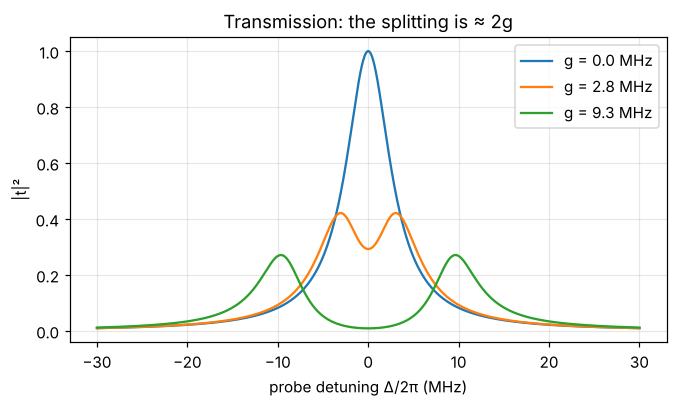

In [3]:
D = np.linspace(-30, 30, 1200)
for xi in (0, 0.3, 1.0):
    g = r["g0"] * xi
    t = r["kappa"] / (r["kappa"] - 1j * D + g**2 / (r["gamma"] - 1j * D))
    plt.plot(D, abs(t) ** 2, label=f"g = {g:.1f} MHz")
plt.xlabel("probe detuning Δ/2π (MHz)"); plt.ylabel("|t|²"); plt.legend(); plt.title("Transmission: the splitting is ≈ 2g")

## 4. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

DECIMALS = dict(g0=2, kappa=2, gamma=2, C=2, FSR_GHz=3, linewidth_MHz=3, N0=3, beta_pct=1, beta_exact_pct=1, F_for_kappa_eq_g=0, R_pct=4)
page = dict(g0=9.26, kappa=3.00, gamma=3.03, C=9.42, V_halflam3=4.13e6, FSR_GHz=299.792, linewidth_MHz=5.996,
            n0=5.37e-2, N0=0.212, beta_pct=90.4, beta_exact_pct=44.9, F_for_kappa_eq_g=16194, R_pct=99.9937)
check(r, page)

          g0: notebook 9.256        page 9.26       OK
       kappa: notebook 2.998        page 3          OK
       gamma: notebook 3.033        page 3.03       OK
           C: notebook 9.424        page 9.42       OK
  V_halflam3: notebook 4.134e+06    page 4.13e+06   OK
     FSR_GHz: notebook 299.8        page 299.792    OK
linewidth_MHz: notebook 5.996        page 5.996      OK
          n0: notebook 0.05367      page 0.0537     OK
          N0: notebook 0.2122       page 0.212      OK
    beta_pct: notebook 90.41        page 90.4       OK
beta_exact_pct: notebook 44.94        page 44.9       OK
F_for_kappa_eq_g: notebook 1.619e+04    page 16194      OK
       R_pct: notebook 99.99        page 99.9937    OK
All values match the page.